# Map MOI, OMIM disease module to gene and variants

In [25]:
import os
import sys
import pandas as pd

In [26]:
input_dir = '../1_inputs'
output_dir = '../3_outputs'

In [27]:
allele_collection_df = pd.read_csv(f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores.tsv', sep='\t', low_memory=False)
allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,SCVsForAggregateGermlineClassification_dbnsfp,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,SCV000232587|SCV000321701|SCV000893215|SCV0009...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,98.91,0.225806
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,SCV000111209|SCV000491300|SCV000692643|SCV0006...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,98.39,0.097561
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,SCV000697586|SCV001422687|SCV001713036|SCV0020...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,98.35,0.052419
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,SCV000513395,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,93.30,0.500000
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,SCV000589376|SCV002011544|SCV002512603|SCV0025...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,88.17,0.443548
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,SCV000513398,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,97.95,0.705645
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,SCV001583928|SCV002074112|SCV002655406,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,70.32,0.838710


In [28]:
# Extract OMIM data from PhenotypeIDS and store in OMIM_IDs column
allele_collection_df['OMIM_IDs'] = allele_collection_df['PhenotypeIDS'].str.extractall(r'OMIM:(\d+)')[0].groupby(level=0).apply(list)

allele_collection_df

,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,SCVsForAggregateSomaticClinicalImpact_dbnsfp,SCVsForAggregateOncogenicityClassification_dbnsfp,clinvar_nt_change_dbnsfp,clinvar_aa_change_dbnsfp,RefSeq_mRNA_dbnsfp,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,-,-,887G>A,Arg296Gln,NM_000157.4,2.0,1_Pathogenic,98.91,0.225806,"[608013, 230800, 230900, 231000, 231005, 16860..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,-,-,1448T>C,Leu483Pro,NM_000157.4,2.0,1_Pathogenic,98.39,0.097561,"[230900, 230800, 231000, 168600, 608013, 23080..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,-,-,259C>T,Arg87Trp,NM_000157.4,2.0,1_Pathogenic,98.35,0.052419,"[230800, 127750, 168600]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,-,-,197T>A,Leu66His,NM_018684.4,NaN,1_Pathogenic,93.30,0.500000,[314580]
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,-,-,593G>A,Arg198Gln,NM_018684.4,2.0,1_Pathogenic,88.17,0.443548,"[314580, 301041]"
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,-,-,53G>A,Arg18Lys,NM_018684.4,NaN,1_Pathogenic,97.95,0.705645,[314580]
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,-,-,637C>T,Arg213Trp,NM_018684.4,2.0,1_Pathogenic,70.32,0.838710,[314580]


In [29]:
# Load inheritance mapping from previously generated file
inheritance_df = pd.read_csv(f'{output_dir}/inheritance_mapping.csv')
inheritance_dict = inheritance_df.set_index(['orf_id', 'nt_change', 'aa_change'])['inheritance_clean'].to_dict()
inheritance_source_dict = inheritance_df.set_index(['orf_id', 'nt_change', 'aa_change'])['inheritance_source'].to_dict()

print(f"Loaded {len(inheritance_dict)} inheritance mappings")
print("Inheritance patterns found:")
print(inheritance_df['inheritance_clean'].value_counts())
print("Inheritance sources found:")
print(inheritance_df['inheritance_source'].value_counts())

Loaded 8775 inheritance mappings
Inheritance patterns found:
inheritance_clean
autosomal recessive    3199
autosomal dominant     2248
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64
Inheritance sources found:
inheritance_source
OMIM     6632
GenCC     181
Name: count, dtype: int64


In [30]:
# Load disease modules mapping from previously generated file
disease_modules_df = pd.read_csv(f'{output_dir}/disease_modules_to_genes.tsv', sep='\t')

# Create a mapping from gene symbol to disease modules
gene_to_modules = {}
for _, row in disease_modules_df.iterrows():
    if pd.notna(row['genes']) and row['genes']:  # Check if genes column is not empty
        gene_list = row['genes'].split(';')
        for gene in gene_list:
            if gene not in gene_to_modules:
                gene_to_modules[gene] = []
            gene_to_modules[gene].append(row['disease_module'])

print(f"Loaded {len(disease_modules_df)} disease modules")
print(f"Mapped {len(gene_to_modules)} genes to disease modules")
print("Disease modules:")
print(disease_modules_df['disease_module'].tolist())

Loaded 28 disease modules
Mapped 1273 genes to disease modules
Disease modules:
['Rare genetic vascular disease', 'Rare genetic systemic or rheumatologic disease', 'Rare genetic eye disease', 'Rare genetic gynecological and obstetrical diseases', 'Rare genetic immune disease', 'Rare genetic cardiac disease', 'Rare genetic renal disease', 'Rare genetic developmental defect during embryogenesis', 'Rare genetic bone disease', 'Rare genetic odontologic disease', 'Rare genetic hematologic disease', 'Laminopathy', 'Ciliopathy', 'Genetic otorhinolaryngologic disease', 'Rare genetic urogenital disease', 'Rare genetic respiratory disease', 'Rare genetic hepatic disease', 'Rare genetic endocrine disease', 'Rare genetic neurological disorder', 'RASopathy', 'Serpinopathy', 'Rare genetic gastroenterological disease', 'Rare inborn errors of metabolism', 'Genetic infertility', 'Rare genetic skin disease', 'Rare chromosomal anomaly', 'Rare genetic tumor', 'Inherited cancer-predisposing syndrome']


In [31]:
# Load OMIM data to get disease names
omim_df = pd.read_csv(f'{input_dir}/mimTitles.txt', sep="\t", skiprows=2)
omim_df.dropna(subset=['MIM Number'], inplace=True)
omim_df['MIM Number'] = omim_df['MIM Number'].astype(int)
omim_df['disease_name'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[0])
omim_df['Symbol'] = omim_df['Preferred Title; symbol'].apply(lambda x: x if x != x else x.split(';')[-1] if ';' in x else None)
omim_df.drop(columns=['Preferred Title; symbol'], inplace=True)

# Create mapping dictionary from OMIM ID to disease name
omim_id_to_name = omim_df.set_index('MIM Number')['disease_name'].to_dict()

print(f"Loaded {len(omim_id_to_name)} OMIM disease names")
print("Sample OMIM mappings:")
for i, (omim_id, name) in enumerate(list(omim_id_to_name.items())[:5]):
    print(f"  {omim_id}: {name}")
print("...")

Loaded 29102 OMIM disease names
Sample OMIM mappings:
  100050: AARSKOG SYNDROME, AUTOSOMAL DOMINANT
  100070: AORTIC ANEURYSM, FAMILIAL ABDOMINAL, 1
  100100: PRUNE BELLY SYNDROME
  100200: ABDUCENS PALSY
  100300: ADAMS-OLIVER SYNDROME 1
...


In [32]:
# Map inheritance patterns to the allele collection dataframe
allele_collection_df['inheritance_pattern'] = None

for i, row in allele_collection_df.iterrows():
    # Create key for inheritance mapping
    key = (row['orf_id'], row['nt_change'], row['aa_change'])
    if key in inheritance_dict:
        allele_collection_df.at[i, 'inheritance_pattern'] = inheritance_dict[key]

print("Inheritance mapping results:")
print(allele_collection_df['inheritance_pattern'].value_counts(dropna=False))

Inheritance mapping results:
inheritance_pattern
autosomal recessive    3199
NaN                    2341
autosomal dominant     2247
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64


In [33]:
# Map inheritance patterns to the allele collection dataframe
allele_collection_df['inheritance_source'] = None

for i, row in allele_collection_df.iterrows():
    # Create key for inheritance mapping
    key = (row['orf_id'], row['nt_change'], row['aa_change'])
    if key in inheritance_source_dict:
        allele_collection_df.at[i, 'inheritance_source'] = inheritance_source_dict[key]

print("Inheritance source mapping results:")
print(allele_collection_df['inheritance_source'].value_counts(dropna=False))

Inheritance source mapping results:
inheritance_source
OMIM     6631
NaN      2341
GenCC     181
Name: count, dtype: int64


In [34]:
# Map disease modules to the allele collection dataframe
allele_collection_df['disease_modules'] = None
allele_collection_df['disease_module_count'] = 0

for i, row in allele_collection_df.iterrows():
    if pd.notna(row['symbol']) and row['symbol'] in gene_to_modules:
        modules = gene_to_modules[row['symbol']]
        allele_collection_df.at[i, 'disease_modules'] = '; '.join(modules)
        allele_collection_df.at[i, 'disease_module_count'] = len(modules)

print("Disease module mapping results:")
print(f"Genes with disease modules: {allele_collection_df['disease_module_count'].gt(0).sum()}")
print(f"Genes without disease modules: {allele_collection_df['disease_module_count'].eq(0).sum()}")
print("\nDisease module count distribution:")
print(allele_collection_df['disease_module_count'].value_counts().sort_index())

Disease module mapping results:
Genes with disease modules: 8244
Genes without disease modules: 909

Disease module count distribution:
disease_module_count
0      909
1     1586
2     2170
3     1760
4      947
5      517
6      307
7      546
8      191
9       62
10      14
11      77
12      35
13      32
Name: count, dtype: int64


In [35]:
# Map OMIM disease names to the allele collection dataframe
allele_collection_df['OMIM_disease_names'] = None

for i, row in allele_collection_df.iterrows():
    omim_ids = row['OMIM_IDs']
    if isinstance(omim_ids, list) and len(omim_ids) > 0:
        disease_names = []
        for omim_id in omim_ids:
            omim_int = int(omim_id)
            if omim_int in omim_id_to_name:
                disease_names.append(omim_id_to_name[omim_int])
            else:
                disease_names.append(f"OMIM:{omim_id} (name not found)")
        allele_collection_df.at[i, 'OMIM_disease_names'] = '; '.join(disease_names)

print("OMIM disease name mapping results:")
print(f"Variants with OMIM disease names: {allele_collection_df['OMIM_disease_names'].notna().sum()}")
print(f"Variants without OMIM disease names: {allele_collection_df['OMIM_disease_names'].isna().sum()}")

OMIM disease name mapping results:
Variants with OMIM disease names: 6883
Variants without OMIM disease names: 2270


In [36]:
# Summary statistics of the enhanced dataframe
print("=== MAPPING SUMMARY ===")
print(f"Total variants: {len(allele_collection_df)}")
print(f"Variants with OMIM IDs: {allele_collection_df['OMIM_IDs'].notna().sum()}")
print(f"Variants with OMIM disease names: {allele_collection_df['OMIM_disease_names'].notna().sum()}")
print(f"Variants with inheritance patterns: {allele_collection_df['inheritance_pattern'].notna().sum()}")
print(f"Variants with disease modules: {allele_collection_df['disease_modules'].notna().sum()}")

print("\n=== INHERITANCE PATTERNS ===")
print(allele_collection_df['inheritance_pattern'].value_counts(dropna=False))

print("\n=== DISEASE MODULES COVERAGE ===")
for module in disease_modules_df['disease_module'].tolist():
    count = allele_collection_df['disease_modules'].str.contains(module, na=False).sum()
    print(f"{module}: {count} variants")

# Display the enhanced dataframe
print("\n=== ENHANCED DATAFRAME ===")
allele_collection_df[['symbol', 'aa_change', 'OMIM_IDs', 'OMIM_disease_names', 'inheritance_pattern', 'disease_modules', 'disease_module_count']].head(10)

=== MAPPING SUMMARY ===
Total variants: 9153
Variants with OMIM IDs: 6883
Variants with OMIM disease names: 6883
Variants with inheritance patterns: 6812
Variants with disease modules: 8244

=== INHERITANCE PATTERNS ===
inheritance_pattern
autosomal recessive    3199
NaN                    2341
autosomal dominant     2247
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64

=== DISEASE MODULES COVERAGE ===
Rare genetic vascular disease: 112 variants
Rare genetic systemic or rheumatologic disease: 242 variants
Rare genetic eye disease: 2923 variants
Rare genetic gynecological and obstetrical diseases: 539 variants
Rare genetic immune disease: 665 variants
Rare genetic cardiac diseas

,symbol,aa_change,OMIM_IDs,OMIM_disease_names,inheritance_pattern,disease_modules,disease_module_count
0,GBA1,Val54Leu,NaN,None,NaN,None,0
1,GBA1,Leu224Phe,NaN,None,NaN,None,0
2,GBA1,Arg296Gln,"[608013, 230800, 230900, 231000, 231005, 16860...","GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS...",multiple,None,0
3,GBA1,Leu483Pro,"[230900, 230800, 231000, 168600, 608013, 23080...","GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP...",multiple,None,0
4,GBA1,Arg87Trp,"[230800, 127750, 168600]","GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; ...",multiple,None,0
5,GBA1,Arg159Gln,"[230800, 608013, 231005, 230800, 230900, 231000]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, PERI...",autosomal recessive,None,0
6,GBA1,Lys196Gln,[230800],"GAUCHER DISEASE, TYPE I",autosomal recessive,None,0
7,GBA1,Arg209Cys,"[230800, 230900, 231005, 231000, 230800]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE...",autosomal recessive,None,0
8,GBA1,Trp223Arg,"[230800, 230900, 231000]","GAUCHER DISEASE, TYPE I; GAUCHER DISEASE, TYPE...",autosomal recessive,None,0
9,GBA1,Arg202Gln,NaN,None,NaN,None,0


In [37]:
# Save the enhanced dataframe with OMIM, inheritance, and disease module mappings
output_filename = f'{output_dir}/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv'
allele_collection_df.to_csv(output_filename, sep='\t', index=False)

print(f"Enhanced allele collection saved to: {output_filename}")
print(f"Added columns: OMIM_IDs, OMIM_disease_names, inheritance_pattern, disease_modules, disease_module_count")

# Display final dataframe
allele_collection_df

Enhanced allele collection saved to: ../3_outputs/varchamp_seq_confirm_alleles_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv
Added columns: OMIM_IDs, OMIM_disease_names, inheritance_pattern, disease_modules, disease_module_count


,symbol,ensembl_gene_id,orf_id,mut_id,ccsb_mutation_id,ccsb_allele_id,spdi,nt_change,aa_change,collection,...,StarStatus_dbnsfp,clinvar_clnsig_clean_dbnsfp,plddt,rsa,OMIM_IDs,inheritance_pattern,inheritance_source,disease_modules,disease_module_count,OMIM_disease_names
0,GBA1,ENSG00000177628,2,6.0,CCSBVarC000001,ALE0000584,NC_000001.11:155240033:C:G,160G>C,Val54Leu,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,0,None
1,GBA1,ENSG00000177628,2,73.0,CCSBVarC000002,ALE00000002,NC_000001.11:155238225:G:A,670C>T,Leu224Phe,RC4,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,None,0,None
2,GBA1,ENSG00000177628,2,113.0,CCSBVarC000003,ALE00000003,NC_000001.11:155237453:C:T,887G>A,Arg296Gln,RC4,...,2.0,1_Pathogenic,98.91,0.225806,"[608013, 230800, 230900, 231000, 231005, 16860...",multiple,OMIM,None,0,"GAUCHER DISEASE, PERINATAL LETHAL; GAUCHER DIS..."
3,GBA1,ENSG00000177628,2,231.0,CCSBVarC000004,ALE00000004,NC_000001.11:155235252:A:G,1448T>C,Leu483Pro,RC4,...,2.0,1_Pathogenic,98.39,0.097561,"[230900, 230800, 231000, 168600, 608013, 23080...",multiple,OMIM,None,0,"GAUCHER DISEASE, TYPE II; GAUCHER DISEASE, TYP..."
4,GBA1,ENSG00000177628,2,213510.0,CCSBVarC003869,ALE00003869,NC_000001.11:155239934:G:A,259C>T,Arg87Trp,CEGS2,...,2.0,1_Pathogenic,98.35,0.052419,"[230800, 127750, 168600]",multiple,OMIM,None,0,"GAUCHER DISEASE, TYPE I; DEMENTIA, LEWY BODY; ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,ZC4H2,NaN,4320,NaN,CCSBVarC009188,NaN,NC_000023.11:64921845:A:T,197T>A,Leu66His,NaN,...,NaN,1_Pathogenic,93.30,0.500000,[314580],x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME
9149,ZC4H2,NaN,4320,NaN,CCSBVarC009191,NaN,NC_000023.11:64917865:C:T,593G>A,Arg198Gln,NaN,...,2.0,1_Pathogenic,88.17,0.443548,"[314580, 301041]",x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME; WIEACKER-WOLFF SYNDRO...
9150,ZC4H2,NaN,4320,NaN,CCSBVarC009194,NaN,NC_000023.11:64976325:C:T,53G>A,Arg18Lys,NaN,...,NaN,1_Pathogenic,97.95,0.705645,[314580],x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME
9151,ZC4H2,NaN,4320,NaN,CCSBVarC009197,NaN,NC_000023.11:64917821:G:A,637C>T,Arg213Trp,NaN,...,2.0,1_Pathogenic,70.32,0.838710,[314580],x-linked recessive,OMIM,Rare genetic developmental defect during embry...,2,WIEACKER-WOLFF SYNDROME


In [38]:
clean_output_filename = f"{output_dir}/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv"
allele_collection_df[allele_collection_df["entry_seq_final"]=="Y"].to_csv(
    clean_output_filename, 
    sep='\t', index=False
)

print(f"VarChAMP clean allele collection saved to: {clean_output_filename}")

VarChAMP clean allele collection saved to: ../3_outputs/varchamp_clean_allele_collection_clinvar_gnomad_dbnsfp_struc_scores_OMIM_MOI_disease_modules.tsv


In [39]:
allele_collection_df.clinvar_clnsig_clean.value_counts(dropna=False)

clinvar_clnsig_clean
1_Pathogenic     4727
4_VUS            1205
3_Conflicting    1116
6_No_ClinVar      961
2_Benign          703
5_Others          441
Name: count, dtype: int64

In [40]:
allele_collection_df.plddt.value_counts(dropna=False)

plddt
NaN      1204
98.76      42
98.84      42
98.89      42
98.88      39
         ... 
78.88       1
77.87       1
83.21       1
91.24       1
78.85       1
Name: count, Length: 2502, dtype: int64

In [41]:
allele_collection_df.plddt

# Drop NaN values before binning
plddt_values = allele_collection_df['plddt'].dropna()

# Define bins and labels
bins = list(range(0, 111, 10))
labels = [f"{i}-{i+10}" for i in range(0, 101, 10)]

# Bin the values
plddt_binned = pd.cut(plddt_values, bins=bins, right=False, labels=labels)

# Count occurrences in each bin
plddt_bin_counts = plddt_binned.value_counts().sort_index()
print(plddt_bin_counts)

print(f"\nTotal RSA values: {len(plddt_values)}")
print(f"Total binned: {plddt_bin_counts.sum()}")
print(f"Missing: {len(plddt_values) - plddt_bin_counts.sum()}")

plddt
0-10          0
10-20         1
20-30        81
30-40       272
40-50       260
50-60       215
60-70       232
70-80       343
80-90       978
90-100     5567
100-110       0
Name: count, dtype: int64

Total RSA values: 7949
Total binned: 7949
Missing: 0


In [42]:
allele_collection_df.rsa

# Drop NaN values before binning
rsa_values = allele_collection_df['rsa'].dropna() * 100

# Define bins and labels - extend to 101 to include 100%
bins = list(range(0, 111, 10))  # Goes to 110 to include 100-110 bin
labels = [f"{i}-{i+10}" for i in range(0, 101, 10)]  # Include 100-110 label

# Bin the values
rsa_binned = pd.cut(rsa_values, bins=bins, right=False, labels=labels)

# Count occurrences in each bin
rsa_bins_counts = rsa_binned.value_counts().sort_index()
print(rsa_bins_counts)

# Check if we're missing any values
print(f"\nTotal RSA values: {len(rsa_values)}")
print(f"Total binned: {rsa_bins_counts.sum()}")
print(f"Missing: {len(rsa_values) - rsa_bins_counts.sum()}")

rsa
0-10       2964
10-20       879
20-30       671
30-40       584
40-50       558
50-60       572
60-70       473
70-80       377
80-90       399
90-100      315
100-110     157
Name: count, dtype: int64

Total RSA values: 7949
Total binned: 7949
Missing: 0


In [43]:
rsa_bins_counts.sum()

7949

In [44]:
allele_collection_df.rsa.value_counts().sum()

7949

In [45]:
allele_collection_df.inheritance_pattern.value_counts(dropna=False)

inheritance_pattern
autosomal recessive    3199
NaN                    2341
autosomal dominant     2247
multiple                748
x-linked recessive      407
x-linked                104
x-linked dominant        75
unknown                   8
y-linked                  6
common variant            5
somatic                   5
multifactorial            3
digenic recessive         2
somatic mutation          2
unclear phenotype         1
Name: count, dtype: int64

In [46]:
allele_collection_df.disease_modules.value_counts(dropna=False)

disease_modules
None                                                                                                                                                                                  909
Rare genetic neurological disorder                                                                                                                                                    423
Rare genetic cardiac disease; Rare genetic neurological disorder                                                                                                                      368
Rare genetic neurological disorder; Rare inborn errors of metabolism                                                                                                                  326
Rare genetic hematologic disease                                                                                                                                                      313
                                                      

In [47]:
allele_collection_df[[c for c in allele_collection_df.columns if 'gnomad' in c.lower()]]

,gnomad_af,gnomAD2.1.1_exomes_flag,gnomAD2.1.1_exomes_controls_AC,gnomAD2.1.1_exomes_controls_AN,gnomAD2.1.1_exomes_controls_AF,gnomAD2.1.1_exomes_controls_nhomalt,gnomAD2.1.1_exomes_non_neuro_AC,gnomAD2.1.1_exomes_non_neuro_AN,gnomAD2.1.1_exomes_non_neuro_AF,gnomAD2.1.1_exomes_non_neuro_nhomalt,...,gnomAD4.1_joint_MID_AF,gnomAD4.1_joint_MID_nhomalt,gnomAD4.1_joint_NFE_AC,gnomAD4.1_joint_NFE_AN,gnomAD4.1_joint_NFE_AF,gnomAD4.1_joint_NFE_nhomalt,gnomAD4.1_joint_SAS_AC,gnomAD4.1_joint_SAS_AN,gnomAD4.1_joint_SAS_AF,gnomAD4.1_joint_SAS_nhomalt
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,0.000078,segdup,3,109406,2.742080e-05,0,7,208120,3.363440e-05,0,...,0.000000e+00,0,114,1179874,9.662050e-05,0,0,91078,0.000000e+00,0
3,0.000084,segdup,145,108986,1.330450e-03,0,265,207224,1.278810e-03,0,...,.,.,.,.,.,.,.,.,.,.
4,0.000012,segdup,3,109372,2.742930e-05,0,6,207980,2.884890e-05,0,...,1.650170e-04,0,10,1180008,8.474520e-06,0,2,91086,2.195730e-05,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9148,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.
9149,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.
9150,NaN,.,.,.,.,.,.,.,.,.,...,0.000000e+00,0,0,894933,0.000000e+00,0,0,56759,0.000000e+00,0
9151,NaN,.,.,.,.,.,.,.,.,.,...,.,.,.,.,.,.,.,.,.,.


In [48]:
# Count allele frequencies based on gnomad_af, except for singletons and 2-10 alleles
singletons = 0
two_ten_alleles = 0
zerzerooneperc = 0
zerooneperc = 0
oneperc = 0
morethan10perc = 0
counted_alleles = []


for i, row in allele_collection_df.iterrows():
    if pd.isna(row['gnomAD4.1_joint_AC']):
        continue
    if row['gnomAD4.1_joint_AC'] == 0 or row['gnomAD4.1_joint_AC'] == '.':  # No alleles
        continue
    if int(row['gnomAD4.1_joint_AC']) == 1:  # Singleton
        singletons += 1
        counted_alleles.append(i)
    elif 2 <= int(row['gnomAD4.1_joint_AC']) <= 10:  # 2-10 alleles
        two_ten_alleles += 1
        counted_alleles.append(i)
        
for i, row in allele_collection_df.iterrows():        
    if i in counted_alleles:  # Skip already counted singletons and 2-10 alleles
        continue
    if pd.isna(row['gnomad_af']):
        continue
    elif row['gnomad_af'] < 0.01:  # <0.001%
        zerzerooneperc += 1
    elif row['gnomad_af'] < 0.1:  # <0.01%
        zerooneperc += 1
    elif row['gnomad_af'] < 1:  # <0.1%
        oneperc += 1
    else:  # >10%
        morethan10perc += 1

print(f"Singletons: {singletons}")
print(f"2-10 alleles: {two_ten_alleles}")
print(f"<0.01%: {zerzerooneperc}")
print(f"<0.1%: {zerooneperc}")
print(f"<1%: {oneperc}")
print(f">1%: {morethan10perc}")

Singletons: 586
2-10 alleles: 1295
<0.01%: 3295
<0.1%: 219
<1%: 180
>1%: 0


In [49]:
allele_collection_df[allele_collection_df['gnomAD4.1_joint_AC'] == '1'][['gnomad_af']]

,gnomad_af
14,6.841580e-07
18,NaN
49,6.990040e-07
57,NaN
110,6.845810e-07
...,...
9027,NaN
9045,NaN
9097,6.842630e-07
9110,NaN


In [50]:
disease_modules_count_dict = {}

for i, row in allele_collection_df.iterrows():
    disease_modules = row.disease_modules
    if disease_modules is not None and pd.notna(disease_modules):
        disease_modules_list = disease_modules.split('; ')
        for module in disease_modules_list:
            if module not in disease_modules_count_dict:
                disease_modules_count_dict[module] = 0
            disease_modules_count_dict[module] += 1
            
            
disease_modules_count_dict

{'Rare genetic developmental defect during embryogenesis': 3020,
 'Rare inborn errors of metabolism': 2995,
 'Rare genetic neurological disorder': 3909,
 'Rare genetic eye disease': 2923,
 'Rare genetic bone disease': 1091,
 'Rare genetic immune disease': 665,
 'Rare genetic vascular disease': 112,
 'Rare genetic systemic or rheumatologic disease': 242,
 'Rare genetic gastroenterological disease': 565,
 'Rare genetic hematologic disease': 834,
 'Rare genetic skin disease': 1600,
 'Rare genetic gynecological and obstetrical diseases': 539,
 'Rare genetic renal disease': 1490,
 'Rare genetic hepatic disease': 550,
 'Rare genetic endocrine disease': 1443,
 'Genetic infertility': 740,
 'Serpinopathy': 56,
 'Rare genetic urogenital disease': 196,
 'Ciliopathy': 371,
 'Rare genetic tumor': 658,
 'Inherited cancer-predisposing syndrome': 847,
 'Genetic otorhinolaryngologic disease': 561,
 'Rare genetic cardiac disease': 1090,
 'RASopathy': 170,
 'Rare chromosomal anomaly': 174,
 'Rare genetic

In [51]:
# import rare disease module file
# from https://www.nature.com/articles/s41467-021-26674-1
# supplementary data 5

rd_df = pd.read_csv(f'{input_dir}/rare_disease_modules.txt', sep='\t')

# Add a column with the gene count for each module in rd_df
rd_df['gene_count'] = rd_df['all_genes'].apply(lambda x: len(x.split(';')) if pd.notna(x) and x else 0)
rd_df.to_csv(f'{output_dir}/rare_disease_modules_ALL_GENES_with_gene_count.tsv', sep='\t', index=False)

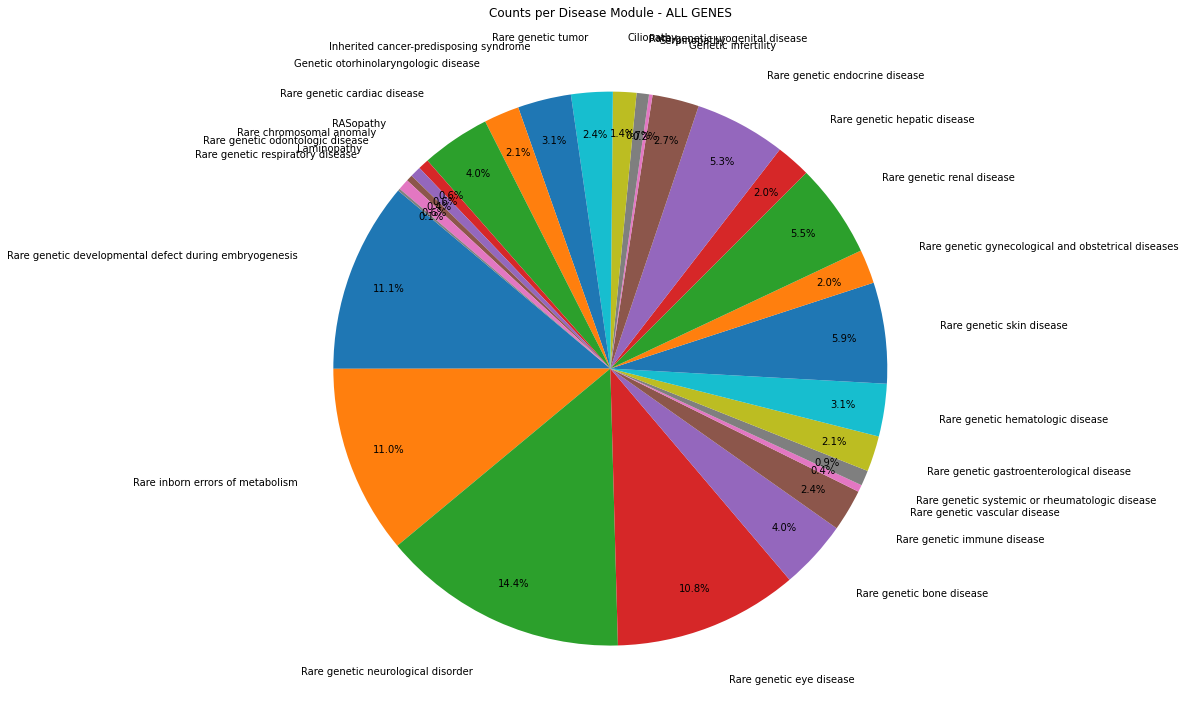

In [52]:
import matplotlib.pyplot as plt

# Pie chart for counts per module using disease_modules_count_dict
labels = list(disease_modules_count_dict.keys())
sizes = list(disease_modules_count_dict.values())

plt.figure(figsize=(16, 16))
plt.pie(sizes, labels=labels, autopct='%1.1f%%', startangle=140, labeldistance=1.2, pctdistance=0.85)
plt.title('Counts per Disease Module - ALL GENES')
plt.tight_layout()
plt.show()